In [1]:
 # %pip install astropy lsdb matplotlib pandas pyarrow s3fs

In [2]:
import astropy.units as u  # Angular units
import lsdb  # Cone search with HATS catalogs
import matplotlib.pyplot as plt  # Plot the spectrum
import pyarrow.compute as pc  # Filter the catalog
import pyarrow.dataset  # Load the catalog
import pyarrow.fs  # Simple S3 filesystem pointer
import pyarrow.parquet  # Load the schema
from astropy.coordinates import SkyCoord  # Distances from the target position

In [3]:
# AWS S3 paths.
s3_bucket = "nasa-irsa-euclid-dr1"
collection_prefix = "contributed/dr1/hats/reformatted_catalogs/mer_catalogue_deep_survey"
catalog_name = "euclid_dr1_reformatted_catalogs_mer_catalogue_deep_survey-hats"

collection_path = f"{s3_bucket}/{collection_prefix}"
dataset_path = f"{collection_path}/{catalog_name}/dataset"
schema_path = f"{dataset_path}/_common_metadata"

# S3 pointer. Use `anonymous=True` to access without credentials.
s3 = pyarrow.fs.S3FileSystem(anonymous=True)

In [4]:
# Load the Parquet schema.
schema = pyarrow.parquet.read_schema(schema_path, filesystem=s3)

print(f"{len(schema)} columns in the {catalog_name} catalog")

483 columns in the euclid_dr1_reformatted_catalogs_mer_catalogue_deep_survey-hats catalog


In [ ]:
schema.names[-3:]

['Norder', 'Dir', 'Npix']

In [6]:
# Access the data type using the `field` method.
schema.field("flux_y_2fwhm_aper")

pyarrow.Field<flux_y_2fwhm_aper: float>

In [7]:
# The column metadata includes unit and description.
# Parquet metadata is always stored as bytestrings, which are denoted by a leading 'b'.
schema.field("flux_y_2fwhm_aper").metadata

{b'unit': b'uJy',
 b'description': b'NIR Y band source aperture photometry flux (2 FWHM diameter) on PSF-matched images',
 b'ucd': b'phot.flux;em.IR.NIR'}

In [8]:
# Find all flux columns.
flux_columns = [name for name in schema.names if name.startswith("flux_")]
print(f"{len(flux_columns)} flux columns. First four are:")
flux_columns[:4]

173 flux columns. First four are:


['flux_vis_1fwhm_aper',
 'flux_vis_2fwhm_aper',
 'flux_vis_3fwhm_aper',
 'flux_vis_4fwhm_aper']

In [9]:
external_flux_columns = [name for name in flux_columns if "ext" in name]
print(f"{len(external_flux_columns)} flux columns from external surveys. First four are:")
external_flux_columns[:4]

136 flux columns from external surveys. First four are:


['flux_u_ext_decam_1fwhm_aper',
 'flux_u_ext_decam_2fwhm_aper',
 'flux_u_ext_decam_3fwhm_aper',
 'flux_u_ext_decam_4fwhm_aper']

In [10]:
dataset = pyarrow.dataset.dataset(dataset_path, partitioning="hive", filesystem=s3, schema=schema)

columns = ["object_id", "ra", "dec", "flux_vis_psf", "point_like_prob"]
bright_point_sources = (
    (pc.field("vis_det") == 1)  # detected in the VIS mosaic
    & (pc.field("spurious_flag") == 0)  # not flagged as spurious
    & (pc.field("point_like_prob") > 0.99)  # point-like
    & (pc.field("flux_vis_psf") > 1_000)  # brighter than 1 mJy in VIS
)

bright_objects = dataset.to_table(columns=columns, filter=bright_point_sources).to_pandas()
bright_objects

,object_id,ra,dec,flux_vis_psf,point_like_prob
0,-654232994482405837,65.423299,-48.240584,1263.177246,0.994798
1,-654765817477541162,65.476582,-47.754116,6028.680176,0.992158
...,...,...,...,...,...
74,-614478250472700124,61.447825,-47.270012,4878.349609,0.993754
75,-610477188462484432,61.047719,-46.248443,2792.606201,0.997514


In [11]:
bright_objects["ra"]

0     65.423299
1     65.476582
        ...    
74    61.447825
75    61.047719
Name: ra, Length: 76, dtype: float64

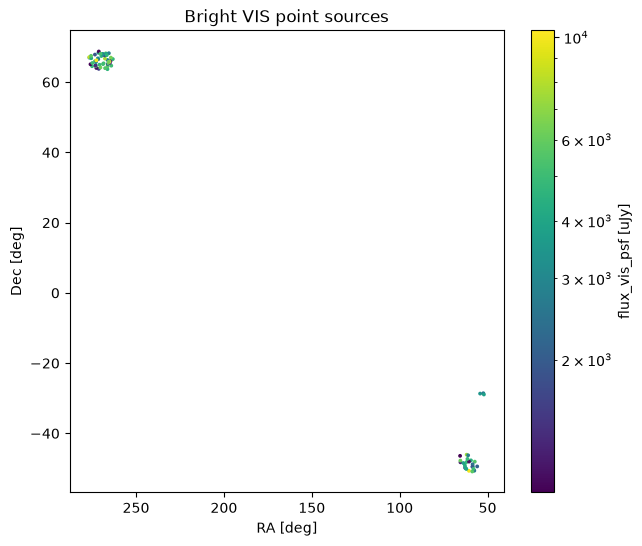

In [13]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(
    bright_objects["ra"],
    bright_objects["dec"],
    c=bright_objects["flux_vis_psf"],
    cmap="viridis",
    norm=LogNorm(),  # fluxes span orders of magnitude
    s=3,
)
fig.colorbar(sc, ax=ax, label="flux_vis_psf [uJy]")
ax.invert_xaxis()  # RA increases to the left on the sky
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title("Bright VIS point sources")
plt.show()

In [14]:
mer_deep = lsdb.open_catalog(
    f"s3://{collection_path}",
    columns=["object_id", "ra", "dec", "flux_vis_psf", "point_like_prob"],
)

ngc6543_ra, ngc6543_dec = 269.6394799, 66.6329765  # degrees
ngc6543_cone = mer_deep.cone_search(ra=ngc6543_ra, dec=ngc6543_dec, radius_arcsec=120)
ngc6543_cone

,object_id,ra,dec,flux_vis_psf,point_like_prob,ra_from_object_id,dec_from_object_id
npartitions=1,,,,,,,
"Order: 5, Pixel: 2901",int64[pyarrow],double[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],double[pyarrow],double[pyarrow]


In [15]:
ngc6543_objects = ngc6543_cone.compute()
ngc6543_objects

Building task graph...


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,object_id,ra,dec,flux_vis_psf,point_like_prob,ra_from_object_id,dec_from_object_id
_healpix_29,,,,,,,
816661021554958734,2696368391665999552,269.636839,66.599955,0.083087,0.000057,269.636839,66.599955
816661021564773739,2696387118665998330,269.638712,66.599833,0.098289,0.0,269.638712,66.599833
...,...,...,...,...,...,...,...
816663509366543382,2696463318666634648,269.646332,66.663465,0.158201,0.000079,269.646332,66.663465
816663510059468650,2696512636666657519,269.651264,66.665752,<NA>,<NA>,269.651264,66.665752


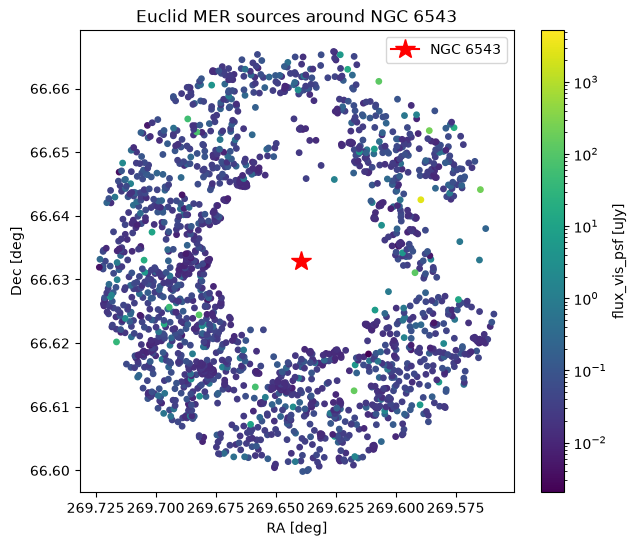

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(
    ngc6543_objects["ra"],
    ngc6543_objects["dec"],
    c=ngc6543_objects["flux_vis_psf"],
    cmap="viridis",
    norm=LogNorm(),
    s=15,
)
ax.plot(ngc6543_ra, ngc6543_dec, marker="*", color="red", markersize=15, label="NGC 6543")
fig.colorbar(sc, ax=ax, label="flux_vis_psf [uJy]")
ax.invert_xaxis()  # RA increases to the left on the sky
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title("Euclid MER sources around NGC 6543")
ax.legend()
plt.show()

In [18]:
spectra_collection_path = f"{s3_bucket}/contributed/dr1/hats/reformatted_catalogs/sir_combined_spectra"
spectra_catalog = lsdb.open_catalog(
    f"s3://{spectra_collection_path}",
    columns=["object_id", "tileid", "lrange", "n_dith", "spectrum"],
)

exdra = SkyCoord(ra=271.05936903 * u.deg, dec=67.90340938 * u.deg)
exdra_spectra = spectra_catalog.cone_search(ra=exdra.ra.deg, dec=exdra.dec.deg, radius_arcsec=1).compute()
exdra_spectra[["object_id", "tileid", "lrange", "n_dith"]]

Building task graph...


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,object_id,tileid,lrange,n_dith
_healpix_29,,,,
1129178778797561084,2710600551679034502,102160337,RGS,4
1129178778797758990,2710600432679034723,102160337,RGS,4
1129178778797763570,2710600167679034755,101838586,BGS,12
1129178778797763570,2710600167679034755,101838586,RGS,36
1129178778797778436,2710599870679034720,102160337,RGS,4
1129178778797780032,2710599814679034740,102160337,RGS,4
1129178778797787883,2710599934679034797,101838586,BGS,12
1129178778797787883,2710599934679034797,101838586,RGS,36
1129178778797792381,2710600028679034865,102160337,RGS,4


In [19]:
spectra_coords = SkyCoord(
    ra=exdra_spectra["ra_from_object_id"].to_numpy() * u.deg, dec=exdra_spectra["dec_from_object_id"].to_numpy() * u.deg
)
offset_arcsec = exdra.separation(spectra_coords).arcsec
best = exdra_spectra.assign(offset_arcsec=offset_arcsec).sort_values(["n_dith", "offset_arcsec"], ascending=[False, True])
exdra_object = exdra_spectra[exdra_spectra["object_id"] == best["object_id"].iloc[0]]
exdra_object[["object_id", "tileid", "lrange", "n_dith"]]

,object_id,tileid,lrange,n_dith
_healpix_29,,,,
1129178778797787883,2710599934679034797,101838586,BGS,12
1129178778797787883,2710599934679034797,101838586,RGS,36


In [20]:
# The spectrum in the first row, as a pandas DataFrame.
exdra_object.iloc[0]["spectrum"]

,wavelength,signal,mask,var,quality,ndith
0,8548.500000,0.0,1,0.0,0.0,0
1,8560.799805,0.0,1,0.0,0.0,0
...,...,...,...,...,...,...
431,13849.799805,0.0,1,0.0,0.0,0
432,13862.099609,0.0,1,0.0,0.0,0


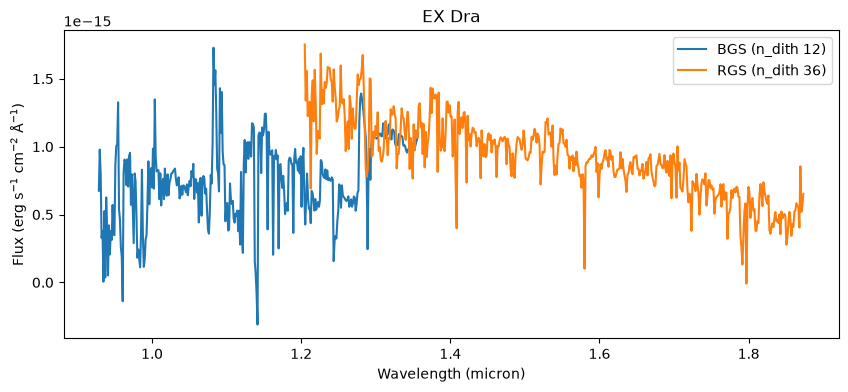

In [21]:
# signal is stored in units of 1e-16 erg/s/cm2/Angstrom (FITS keyword FSCALE). The catalog's unit metadata omits this factor.
FSCALE = 1e-16

fig, ax = plt.subplots(figsize=(10, 4))
for _, row in exdra_object.iterrows():
    spectrum = row["spectrum"]
    bad = (spectrum["mask"] % 2 == 1) | (spectrum["mask"] >= 64)
    flux = spectrum["signal"] * FSCALE
    ax.plot(spectrum["wavelength"] / 1e4, flux.where(~bad), label=f"{row['lrange']} (n_dith {row['n_dith']})")

ax.set_xlabel("Wavelength (micron)")
ax.set_ylabel("Flux (erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")
ax.set_title("EX Dra")
ax.legend()
plt.show()